In [ ]:
from google.colab import files
uploaded = files.upload()

Saving archive (1).zip to archive (1).zip


In [ ]:
import pandas as pd

df = pd.read_csv('archive (1).zip')
df.head()

,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type,Star color,Spectral Class
0,3068,0.002400,0.1700,16.12,0,Red,M
1,3042,0.000500,0.1542,16.60,0,Red,M
2,2600,0.000300,0.1020,18.70,0,Red,M
3,2800,0.000200,0.1600,16.65,0,Red,M
4,1939,0.000138,0.1030,20.06,0,Red,M


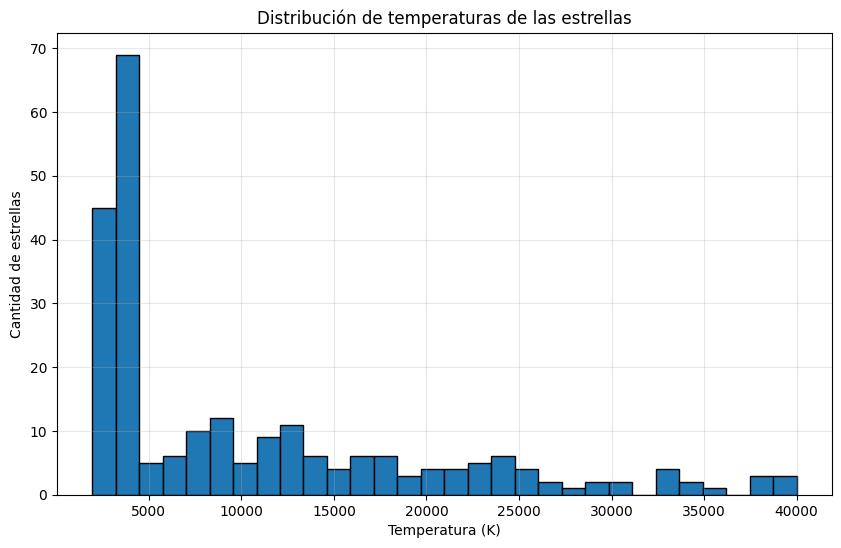

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(df['Temperature (K)'], bins=30, edgecolor='black')

plt.xlabel('Temperatura (K)')
plt.ylabel('Cantidad de estrellas')
plt.title('Distribución de temperaturas de las estrellas')
plt.grid(True, alpha=0.3)

plt.show()

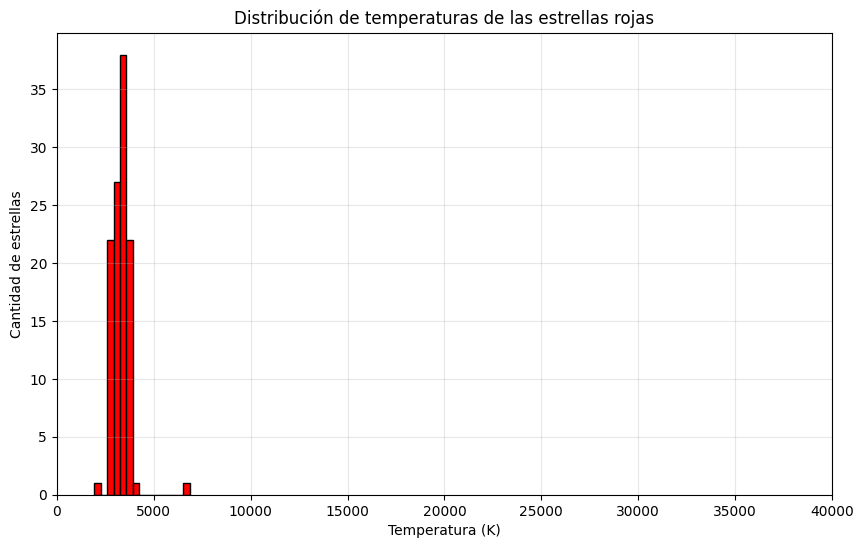

In [ ]:
import matplotlib.pyplot as plt

# Filtrar estrellas rojas
red_stars = df[df['Star color'] == 'Red']

# Histograma de temperaturas
plt.figure(figsize=(10,6))
plt.hist(red_stars['Temperature (K)'], bins=15, color='red', edgecolor='black')

plt.title('Distribución de temperaturas de las estrellas rojas')
plt.xlabel('Temperatura (K)')
plt.ylabel('Cantidad de estrellas')
plt.grid(alpha=0.3)
plt.xlim(0, 40000)

plt.show()

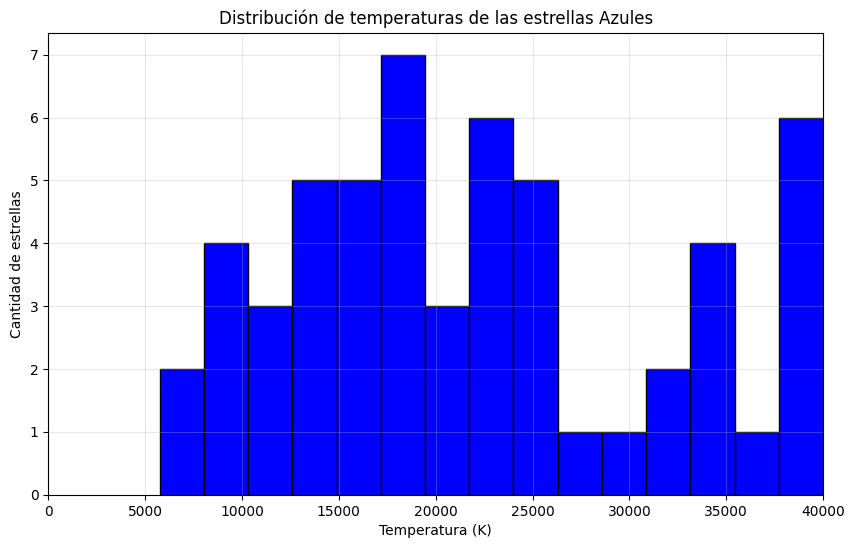

In [ ]:
import matplotlib.pyplot as plt

# Filtrar estrellas rojas
red_stars = df[df['Star color'] == 'Blue']

# Histograma de temperaturas
plt.figure(figsize=(10,6))
plt.hist(red_stars['Temperature (K)'], bins=15, color='Blue', edgecolor='black')

plt.title('Distribución de temperaturas de las estrellas Azules')
plt.xlabel('Temperatura (K)')
plt.ylabel('Cantidad de estrellas')
plt.grid(alpha=0.3)
plt.xlim(0, 40000)

plt.show()

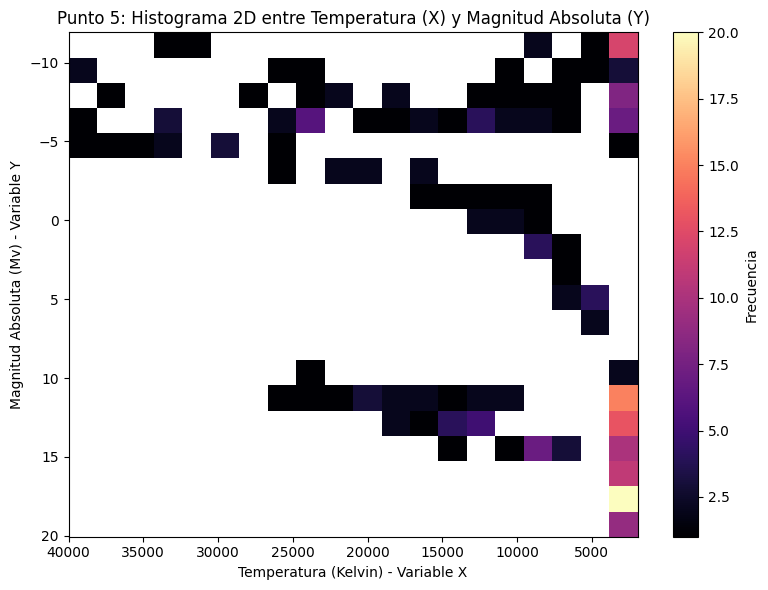

In [ ]:
import matplotlib.pyplot as plt

# Aseguramos que X e Y están definidos (basado en el estado del kernel)
X = df['Temperature (K)']
Y = df['Absolute magnitude(Mv)']

plt.figure(figsize=(8,6))

plt.hist2d(
    X,
    Y,
    bins=(20,20),
    cmap='magma',
    cmin=1
)

plt.colorbar(label='Frecuencia')

plt.xlabel('Temperatura (Kelvin) - Variable X')
plt.ylabel('Magnitud Absoluta (Mv) - Variable Y')
plt.title('Punto 5: Histograma 2D entre Temperatura (X) y Magnitud Absoluta (Y)')

# Corrección: Se usa plt.gca().invert_yaxis() en lugar de plt.invert.Yaxis()
plt.gca().invert_xaxis()
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [ ]:
# Calcular el promedio de la magnitud absoluta y asignarlo a mu_y
mu_y = df['Absolute magnitude(Mv)'].mean()

print(f'El promedio de la magnitud absoluta (mu_y) es: {mu_y:.2f}')

El promedio de la magnitud absoluta (mu_y) es: 4.38


In [ ]:
import numpy as np

# 1. Calcular el porcentaje de datos que son menores o iguales a mu_y
percentil_mu_y = (df['Absolute magnitude(Mv)'] <= mu_y).mean() * 100

# 2. Queremos un intervalo que cubra el 25% adicional
percentil_objetivo = percentil_mu_y + 25

# 3. Encontrar el valor y_up que corresponde a ese percentil acumulado
y_up = np.percentile(df['Absolute magnitude(Mv)'], percentil_objetivo)

print(f'Promedio (mu_y): {mu_y:.2f}')
print(f'Percentil en mu_y: {percentil_mu_y:.2f}%')
print(f'Percentil objetivo (mu_y + 25%): {percentil_objetivo:.2f}%')
print(f'Valor y_up encontrado: {y_up:.2f}')

# Verificación
conteo_intervalo = df[(df['Absolute magnitude(Mv)'] >= mu_y) & (df['Absolute magnitude(Mv)'] <= y_up)].shape[0]
porcentaje_real = (conteo_intervalo / len(df)) * 100
print(f'\nVerificación: El {porcentaje_real:.2f}% de los datos están en [mu_y, y_up]')

Promedio (mu_y): 4.38
Percentil en mu_y: 46.67%
Percentil objetivo (mu_y + 25%): 71.67%
Valor y_up encontrado: 13.08

Verificación: El 25.00% de los datos están en [mu_y, y_up]


In [ ]:
#estimación parametros temperatura
import pandas as pd
import numpy as np
from scipy import stats

# Cargar datos
df = pd.read_csv('archive (1).zip')

# Variable X = temperatura
x = df['Temperature (K)']

# Estadísticos muestrales
n = len(x)
media = np.mean(x)
desv = np.std(x, ddof=1)
varianza = np.var(x, ddof=1)

print(f"Tamaño de muestra: {n}")
print(f"Media muestral: {media:.2f}")
print(f"Varianza muestral: {varianza:.2f}")
print(f"Desviación estándar muestral: {desv:.2f}")

# Intervalo de confianza del 95% para la media poblacional
alpha = 0.05
t_crit = stats.t.ppf(1 - alpha/2, n-1)
error = t_crit * desv / np.sqrt(n)

LI = media - error
LS = media + error

print("\nEstimación de la media poblacional")
print(f"IC 95%: ({LI:.2f}, {LS:.2f})")

Tamaño de muestra: 240
Media muestral: 10497.46
Varianza muestral: 91248824.09
Desviación estándar muestral: 9552.43

Estimación de la media poblacional
IC 95%: (9282.79, 11712.14)


In [ ]:
import numpy as np

# 1. Calcular el porcentaje de datos menores o iguales a mu_y
percentil_mu_y = (df['Absolute magnitude(Mv)'] <= mu_y).mean() * 100

# 2. Restar el 25% para encontrar el límite inferior
percentil_objetivo_down = percentil_mu_y - 25

# 3. Encontrar el valor y_down
y_down = np.percentile(df['Absolute magnitude(Mv)'], percentil_objetivo_down)

print(f'Promedio (mu_y): {mu_y:.2f}')
print(f'Percentil en mu_y: {percentil_mu_y:.2f}%')
print(f'Percentil objetivo (mu_y - 25%): {percentil_objetivo_down:.2f}%')
print(f'Valor y_down encontrado: {y_down:.2f}')

# Verificación
conteo_intervalo_down = df[(df['Absolute magnitude(Mv)'] >= y_down) & (df['Absolute magnitude(Mv)'] <= mu_y)].shape[0]
porcentaje_real_down = (conteo_intervalo_down / len(df)) * 100
print(f'\nVerificación: El {porcentaje_real_down:.2f}% de los datos están en [y_down, mu_y]')

Promedio (mu_y): 4.38
Percentil en mu_y: 46.67%
Percentil objetivo (mu_y - 25%): 21.67%
Valor y_down encontrado: -6.65

Verificación: El 25.00% de los datos están en [y_down, mu_y]


In [ ]:
import pandas as pd

# Verificar el porcentaje de datos en el intervalo [y_down, y_up]
conteo_total_intervalo = df[(df['Absolute magnitude(Mv)'] >= y_down) & (df['Absolute magnitude(Mv)'] <= y_up)].shape[0]
porcentaje_total = (conteo_total_intervalo / len(df)) * 100

print(f'Límite inferior (y_down): {y_down:.2f}')
print(f'Límite superior (y_up): {y_up:.2f}')
print(f'\nVerificación final: El {porcentaje_total:.2f}% de los datos totales están contenidos en el intervalo [y_down, y_up]')

# Mostrar las primeras filas que entran en este rango como muestra
display(df[(df['Absolute magnitude(Mv)'] >= y_down) & (df['Absolute magnitude(Mv)'] <= y_up)].head())

Límite inferior (y_down): -6.65
Límite superior (y_up): 13.08

Verificación final: El 50.00% de los datos totales están contenidos en el intervalo [y_down, y_up]


,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type,Star color,Spectral Class
10,3600,0.0029,0.5100,10.690,1,Red,M
11,3129,0.0122,0.3761,11.790,1,Red,M
13,3628,0.0055,0.3930,10.480,1,Red,M
14,2650,0.0006,0.1400,11.782,1,Red,M
15,3340,0.0038,0.2400,13.070,1,Red,M


In [ ]:
#base de datos depurada.
#tiene 120 registros
import pandas as pd

# Si quieres guardar solo los datos depurados en una nueva variable:
df_filtrado = df[(df['Absolute magnitude(Mv)'] >= y_down) & (df['Absolute magnitude(Mv)'] <= y_up)].copy()

print(f'Registros en original: {len(df)}')
print(f'Registros en filtrada: {len(df_filtrado)}')

# Verificamos que df sigue teniendo todo:
display(df.head())


Registros en original: 240
Registros en filtrada: 120


,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type,Star color,Spectral Class
0,3068,0.002400,0.1700,16.12,0,Red,M
1,3042,0.000500,0.1542,16.60,0,Red,M
2,2600,0.000300,0.1020,18.70,0,Red,M
3,2800,0.000200,0.1600,16.65,0,Red,M
4,1939,0.000138,0.1030,20.06,0,Red,M


In [ ]:
# Calcular la media muestral de la temperatura (K) en el DataFrame original
media_muestral_temp = df['Temperature (K)'].mean()

print(f'La media muestral de la temperatura es: {media_muestral_temp:.2f} K')

La media muestral de la temperatura es: 10497.46 K


In [ ]:
# Calcular la media muestral de la temperatura (K) en el DataFrame depurado
media_muestral_temp = df_filtrado['Temperature (K)'].mean()

print(f'La media muestral de la temperatura es: {media_muestral_temp:.2f} K')

La media muestral de la temperatura es: 13903.16 K


In [ ]:
desviacion_estandar_muestral_temp_depurada = df_filtrado['Temperature (K)'].std()
print(f'La desviación estándar muestral de la temperatura en la base de datos depurada es: {desviacion_estandar_muestral_temp_depurada:.2f} K')

La desviación estándar muestral de la temperatura en la base de datos depurada es: 9751.09 K


In [ ]:
#estimación parametros temperatura
import pandas as pd
import numpy as np
from scipy import stats

# Cargar datos
df = pd.read_csv('archive (1).zip')

# Variable X = temperatura
x = df['Temperature (K)']

# Estadísticos muestrales
n = len(x)
media = np.mean(x)
desv = np.std(x, ddof=1)
varianza = np.var(x, ddof=1)

print(f"Tamaño de muestra: {n}")
print(f"Media muestral: {media:.2f}")
print(f"Varianza muestral: {varianza:.2f}")
print(f"Desviación estándar muestral: {desv:.2f}")

# Intervalo de confianza del 95% para la media poblacional
alpha = 0.05
t_crit = stats.t.ppf(1 - alpha/2, n-1)
error = t_crit * desv / np.sqrt(n)

LI = media - error
LS = media + error

print("\nEstimación de la media poblacional")
print(f"IC 95%: ({LI:.2f}, {LS:.2f})")

Tamaño de muestra: 240
Media muestral: 10497.46
Varianza muestral: 91248824.09
Desviación estándar muestral: 9552.43

Estimación de la media poblacional
IC 95%: (9282.79, 11712.14)


In [ ]:
from scipy.stats import t

alpha = 0.05
gl = n - 1

t_critico = t.ppf(1 - alpha/2, gl)

print(t_critico)

1.9699394059160156
